## Load the dataset

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root
PROJECT_ROOT = Path.cwd().parent

# Dataset location
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "heart_disease.csv"

print(f"Looking for dataset at:\n{DATA_PATH}")
print(f"File exists: {DATA_PATH.exists()}")

Looking for dataset at:
/Users/divyanshu/Desktop/mlops-heart-disease/data/raw/heart_disease.csv
File exists: True


## Load the CSV

In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Dataset loaded successfully!
Rows: 303
Columns: 14


In [4]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## Inspect the columns

In [5]:
print("Column names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Column names:
1. age
2. sex
3. cp
4. trestbps
5. chol
6. fbs
7. restecg
8. thalach
9. exang
10. oldpeak
11. slope
12. ca
13. thal
14. target


In [6]:
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## Check missing values

In [7]:
missing = df.isnull().sum().sort_values(ascending=False)

print("Missing values:")
print(missing)

Missing values:
ca          4
thal        2
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
target      0
dtype: int64


In [8]:
missing_percentage = (
    df.isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Missing-value percentage:")
print(missing_percentage)

Missing-value percentage:
ca          1.320132
thal        0.660066
age         0.000000
sex         0.000000
cp          0.000000
trestbps    0.000000
chol        0.000000
fbs         0.000000
restecg     0.000000
thalach     0.000000
exang       0.000000
oldpeak     0.000000
slope       0.000000
target      0.000000
dtype: float64


## Check duplicates

In [9]:
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


## Check the target

In [10]:
print("Target value counts:")
print(df["target"].value_counts().sort_index())

Target value counts:
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [11]:
print("Target percentages:")
print(
    (df["target"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Target percentages:
target
0    54.13
1    18.15
2    11.88
3    11.55
4     4.29
Name: proportion, dtype: float64


In [12]:
print(df.shape)
print(df.columns)
print(df.isnull().sum())
print(df["target"].value_counts().sort_index())

(303, 14)
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [13]:
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


## Inspect unique values

In [14]:
for column in df.columns:
    print(f"\n--- {column} ---")
    print(df[column].unique())


--- age ---
[63 67 37 41 56 62 57 53 44 52 48 54 49 64 58 60 50 66 43 40 69 59 42 55
 61 65 71 51 46 45 39 68 47 34 35 29 70 77 38 74 76]

--- sex ---
[1 0]

--- cp ---
[1 4 3 2]

--- trestbps ---
[145 160 120 130 140 172 150 110 132 117 135 112 105 124 125 142 128 170
 155 104 180 138 108 134 122 115 118 100 200  94 165 102 152 101 126 174
 148 178 158 192 129 144 123 136 146 106 156 154 114 164]

--- chol ---
[233 286 229 250 204 236 268 354 254 203 192 294 256 263 199 168 239 275
 266 211 283 284 224 206 219 340 226 247 167 230 335 234 177 276 353 243
 225 302 212 330 175 417 197 198 290 253 172 273 213 305 216 304 188 282
 185 232 326 231 269 267 248 360 258 308 245 270 208 264 321 274 325 235
 257 164 141 252 255 201 222 260 182 303 265 309 307 249 186 341 183 407
 217 288 220 209 227 261 174 281 221 205 240 289 318 298 564 246 322 299
 300 293 277 214 207 223 160 394 184 315 409 244 195 196 126 313 259 200
 262 215 228 193 271 210 327 149 295 306 178 237 218 242 319 166 180 311


## Create the class-balance visualization

In [15]:
df_eda = df.copy()

df_eda["target_binary"] = (df_eda["target"] > 0).astype(int)

df_eda["target_binary"].value_counts().sort_index()

target_binary
0    164
1    139
Name: count, dtype: int64

## Plot

/var/folders/7w/g6c5tv8j1mx_r_1t2ysxhyq80000gn/T/ipykernel_99505/2804820657.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([


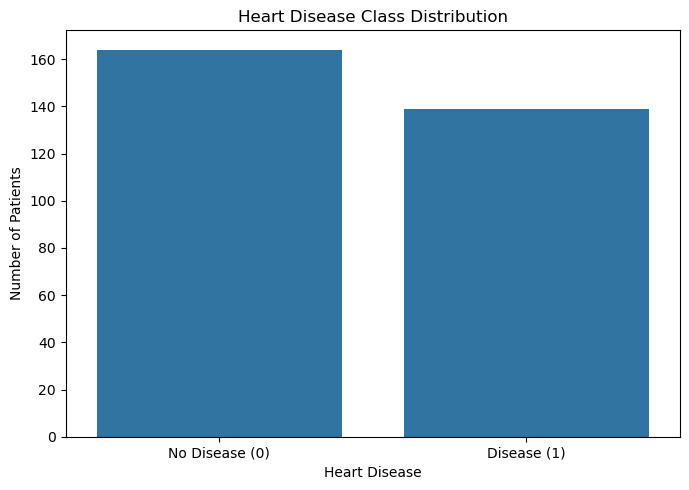

In [16]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df_eda,
    x="target_binary"
)

plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")

ax.set_xticklabels([
    "No Disease (0)",
    "Disease (1)"
])

plt.tight_layout()
plt.show()

## Save the figure

/var/folders/7w/g6c5tv8j1mx_r_1t2ysxhyq80000gn/T/ipykernel_99505/2882888237.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([


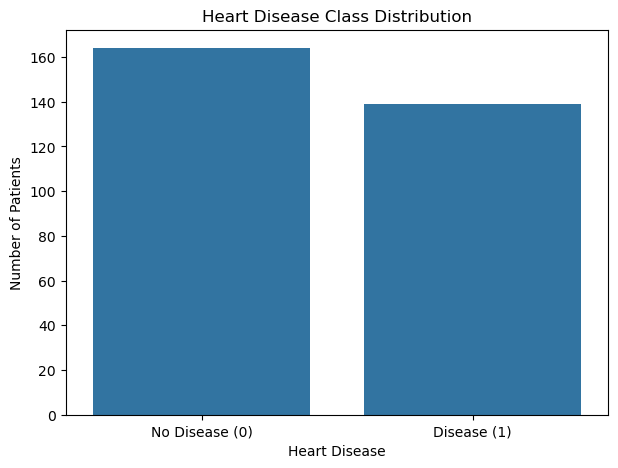

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.countplot(
    data=df_eda,
    x="target_binary",
    ax=ax
)

ax.set_title("Heart Disease Class Distribution")
ax.set_xlabel("Heart Disease")
ax.set_ylabel("Number of Patients")

ax.set_xticklabels([
    "No Disease (0)",
    "Disease (1)"
])

fig.savefig(
    PROJECT_ROOT / "reports" / "figures" / "class_balance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Numerical feature distributions

In [18]:
numeric_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

numeric_columns

['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

## Create histograms

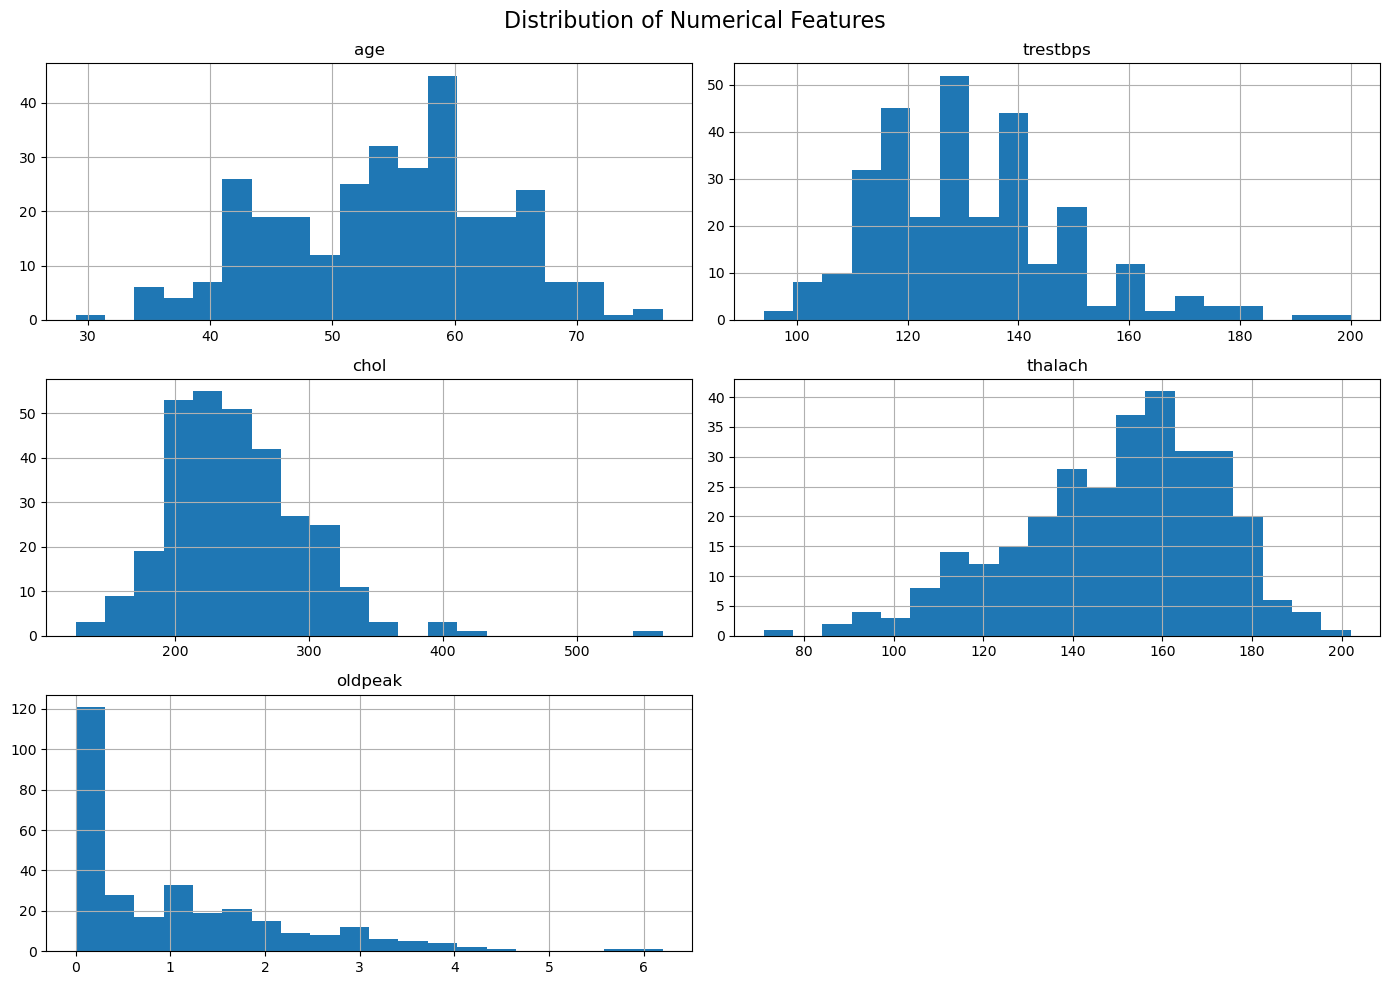

In [19]:
df[numeric_columns].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)

plt.tight_layout()
plt.show()

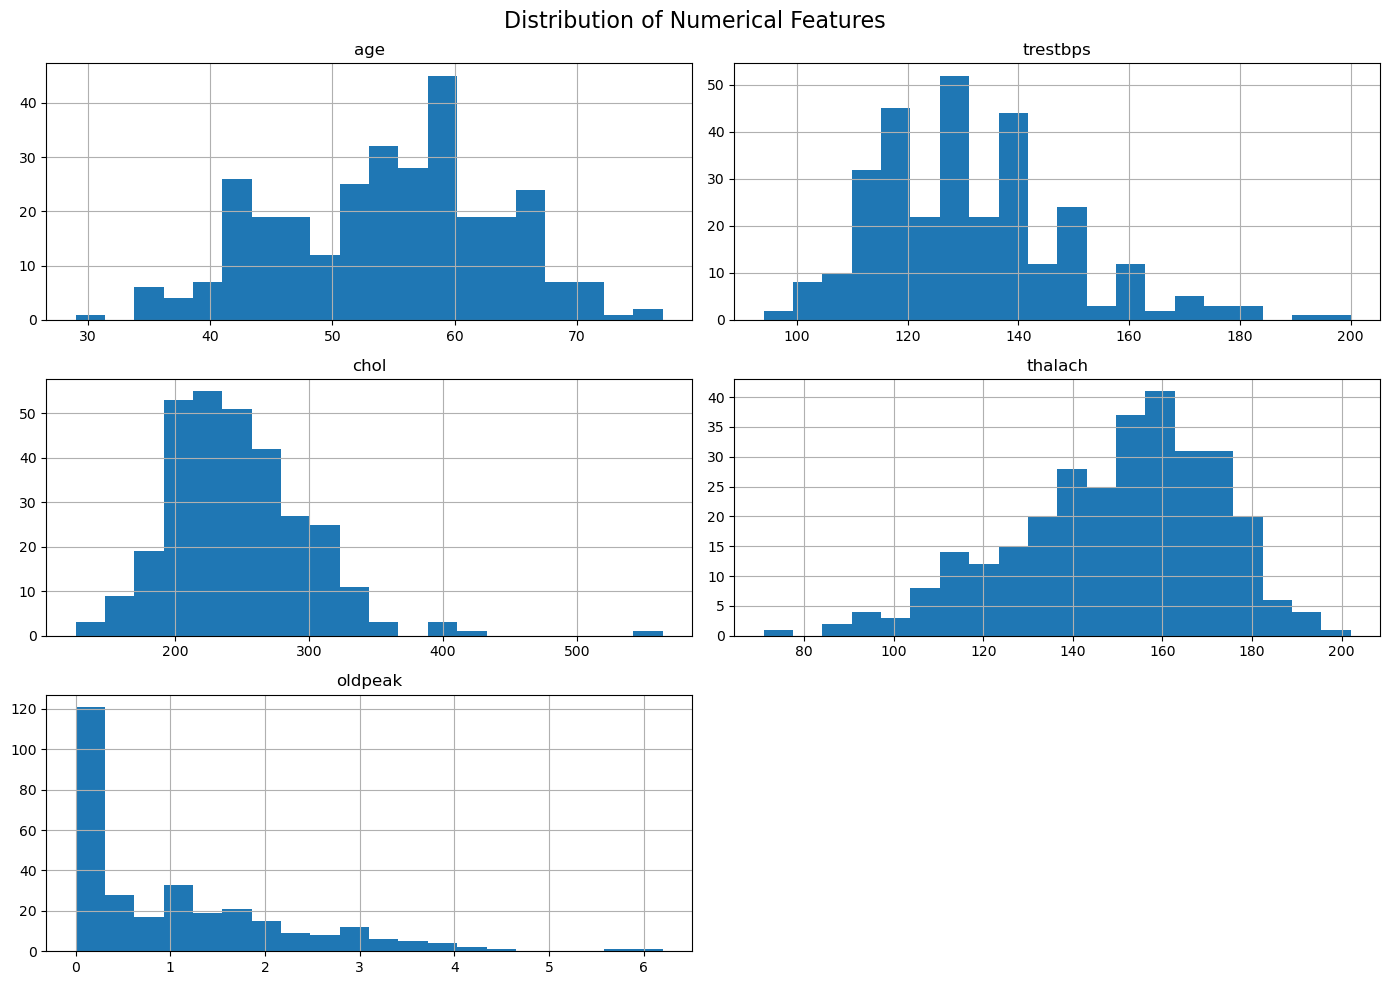

In [20]:
fig = df[numeric_columns].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Correlation heatmap

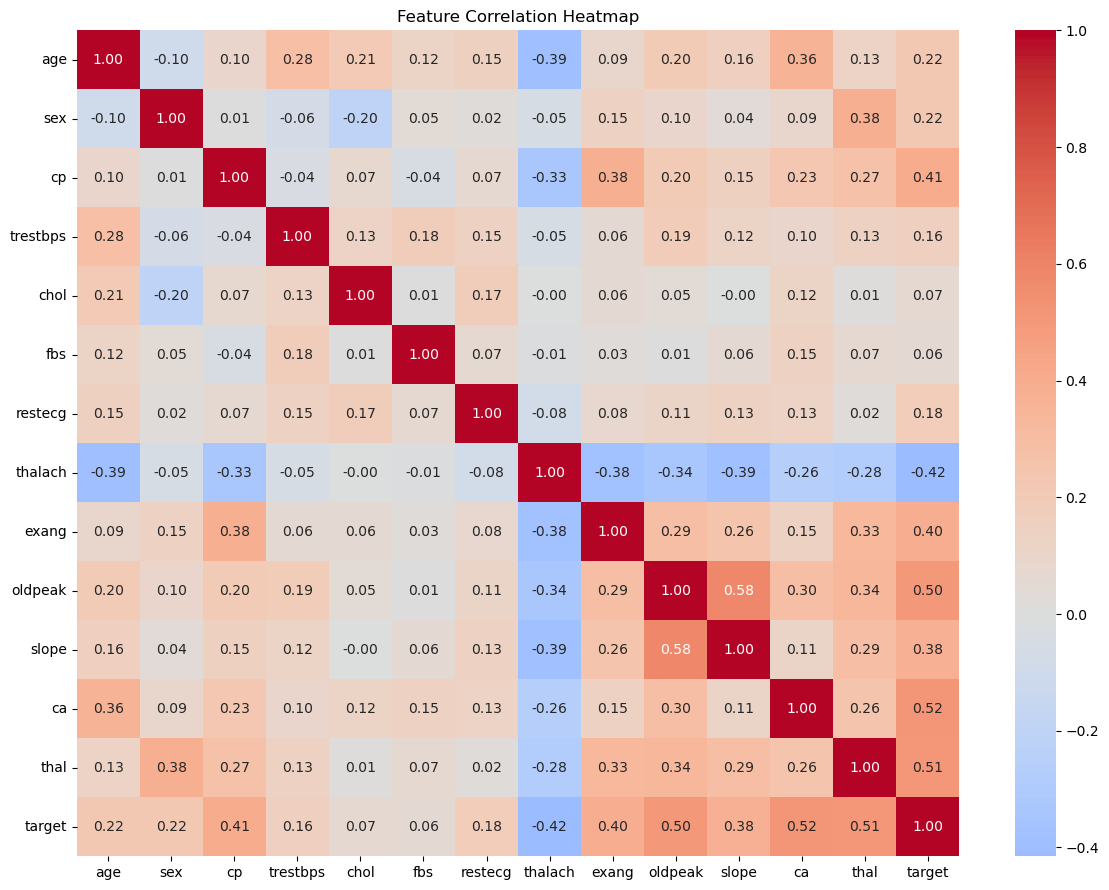

In [21]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

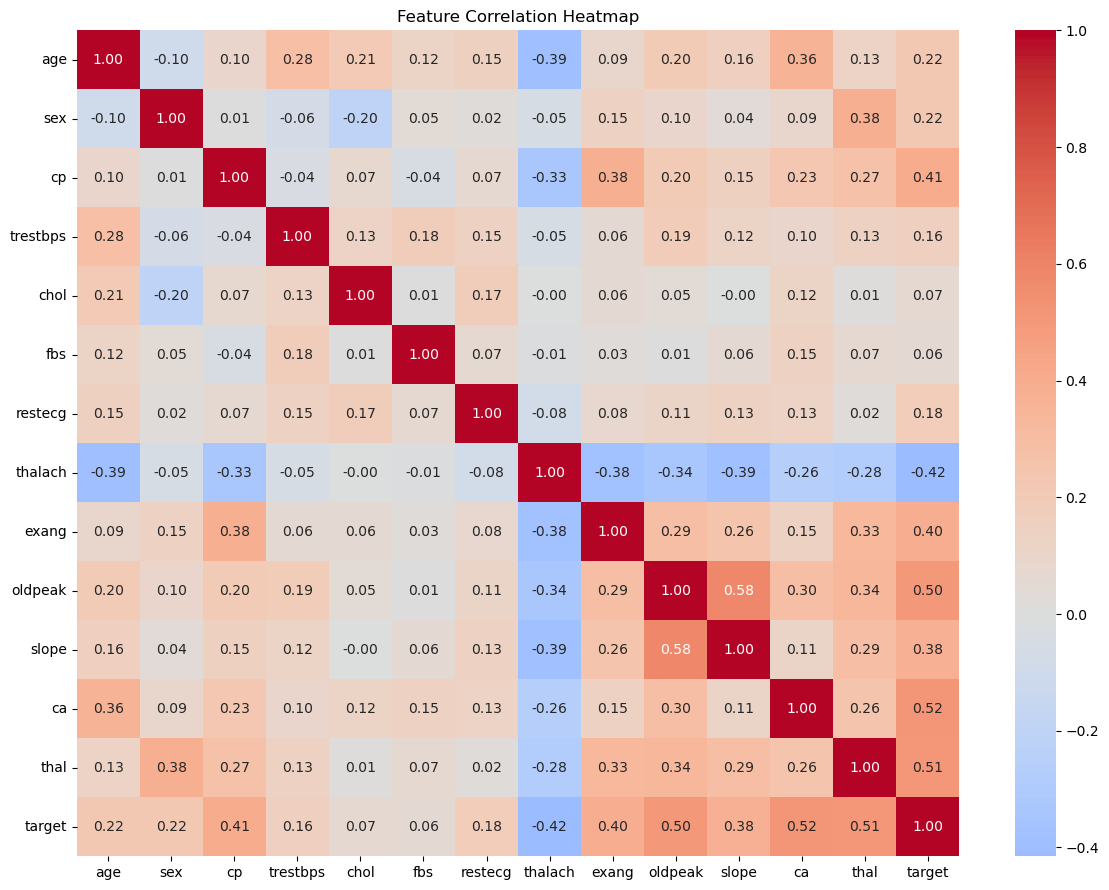

In [22]:
fig = plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()

fig.savefig(
    PROJECT_ROOT / "reports" / "figures" / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Age vs heart disease

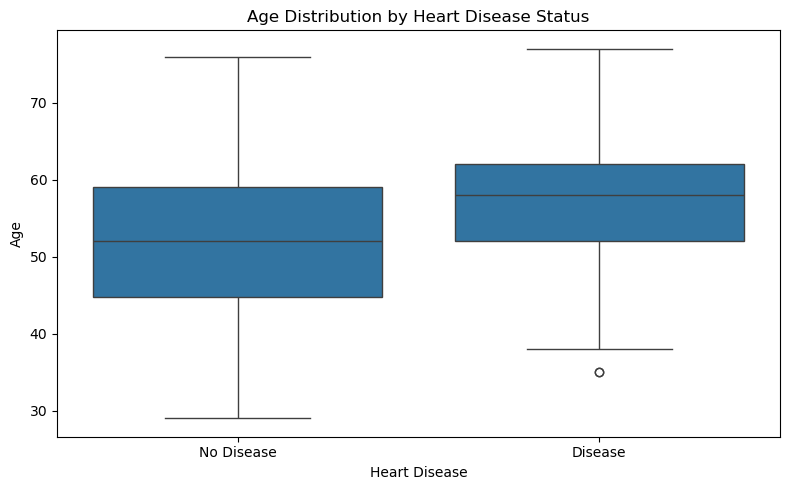

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_eda,
    x="target_binary",
    y="age"
)

plt.title("Age Distribution by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Age")

plt.xticks(
    [0, 1],
    ["No Disease", "Disease"]
)

plt.tight_layout()
plt.show()

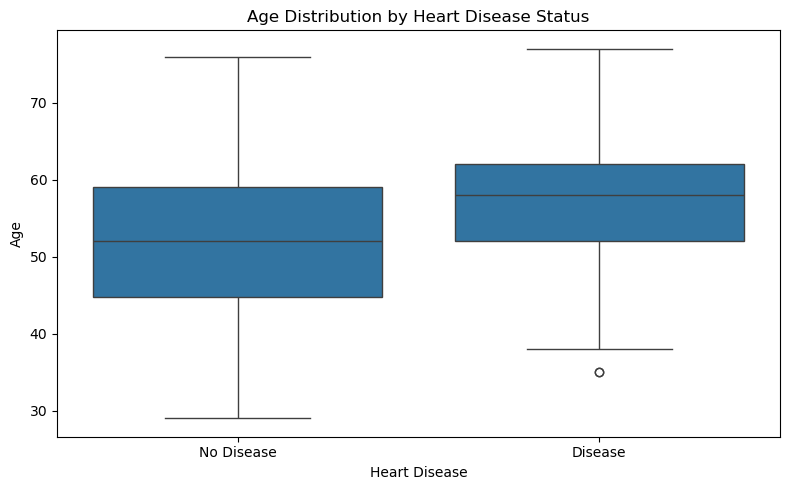

In [24]:
fig = plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_eda,
    x="target_binary",
    y="age"
)

plt.title("Age Distribution by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Age")

plt.xticks(
    [0, 1],
    ["No Disease", "Disease"]
)

plt.tight_layout()

fig.savefig(
    PROJECT_ROOT / "reports" / "figures" / "age_vs_target.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Maximum heart rate vs disease

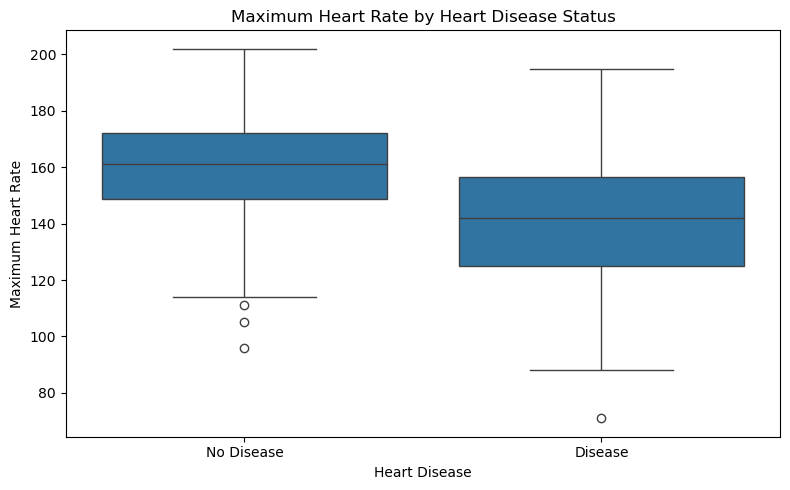

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_eda,
    x="target_binary",
    y="thalach"
)

plt.title("Maximum Heart Rate by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Maximum Heart Rate")

plt.xticks(
    [0, 1],
    ["No Disease", "Disease"]
)

plt.tight_layout()
plt.show()

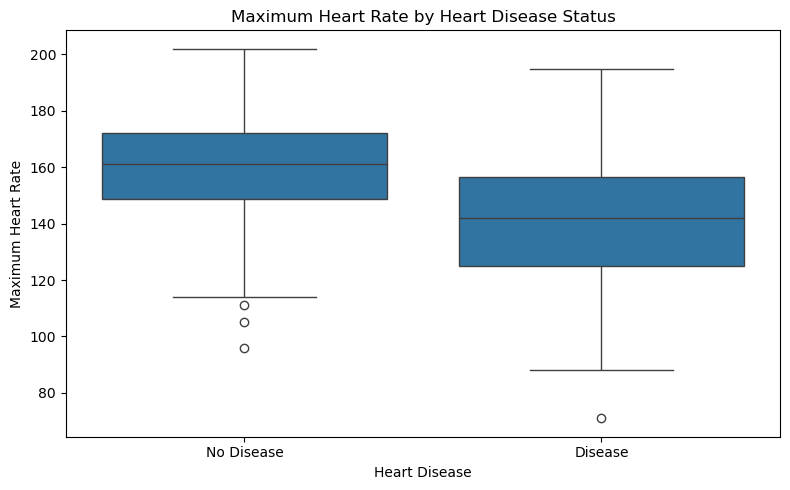

In [26]:
fig = plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_eda,
    x="target_binary",
    y="thalach"
)

plt.title("Maximum Heart Rate by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Maximum Heart Rate")

plt.xticks(
    [0, 1],
    ["No Disease", "Disease"]
)

plt.tight_layout()

fig.savefig(
    PROJECT_ROOT / "reports" / "figures" / "thalach_vs_target.png",
    dpi=300,
    bbox_inches="tight"
)

## Cholesterol vs disease

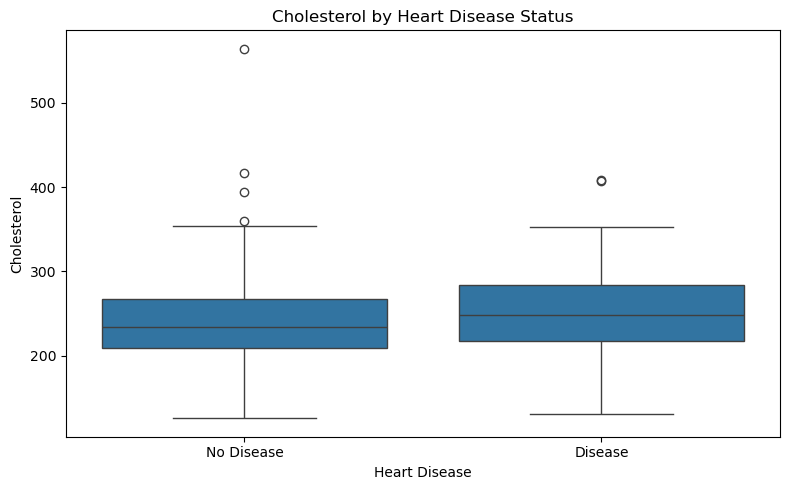

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_eda,
    x="target_binary",
    y="chol"
)

plt.title("Cholesterol by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Cholesterol")

plt.xticks(
    [0, 1],
    ["No Disease", "Disease"]
)

plt.tight_layout()
plt.show()

In [28]:
df_eda.to_csv(
    PROJECT_ROOT / "data" / "processed" / "eda_dataset.csv",
    index=False
)

print("EDA dataset saved successfully.")

EDA dataset saved successfully.


In [29]:
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


In [30]:
for column in df.columns:
    print(f"\n--- {column} ---")
    print(df[column].unique())


--- age ---
[63 67 37 41 56 62 57 53 44 52 48 54 49 64 58 60 50 66 43 40 69 59 42 55
 61 65 71 51 46 45 39 68 47 34 35 29 70 77 38 74 76]

--- sex ---
[1 0]

--- cp ---
[1 4 3 2]

--- trestbps ---
[145 160 120 130 140 172 150 110 132 117 135 112 105 124 125 142 128 170
 155 104 180 138 108 134 122 115 118 100 200  94 165 102 152 101 126 174
 148 178 158 192 129 144 123 136 146 106 156 154 114 164]

--- chol ---
[233 286 229 250 204 236 268 354 254 203 192 294 256 263 199 168 239 275
 266 211 283 284 224 206 219 340 226 247 167 230 335 234 177 276 353 243
 225 302 212 330 175 417 197 198 290 253 172 273 213 305 216 304 188 282
 185 232 326 231 269 267 248 360 258 308 245 270 208 264 321 274 325 235
 257 164 141 252 255 201 222 260 182 303 265 309 307 249 186 341 183 407
 217 288 220 209 227 261 174 281 221 205 240 289 318 298 564 246 322 299
 300 293 277 214 207 223 160 394 184 315 409 244 195 196 126 313 259 200
 262 215 228 193 271 210 327 149 295 306 178 237 218 242 319 166 180 311


 ## Data Cleaning & Preprocessing

In [31]:
categorical_columns = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(sorted(df[column].dropna().unique()))


sex:
[np.int64(0), np.int64(1)]

cp:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

fbs:
[np.int64(0), np.int64(1)]

restecg:
[np.int64(0), np.int64(1), np.int64(2)]

exang:
[np.int64(0), np.int64(1)]

slope:
[np.int64(1), np.int64(2), np.int64(3)]

ca:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]

thal:
[np.float64(3.0), np.float64(6.0), np.float64(7.0)]


## Test the preprocessing pipeline

In [33]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("src available:", (PROJECT_ROOT / "src").exists())

Project root: /Users/divyanshu/Desktop/mlops-heart-disease
src available: True


In [34]:
from src.preprocessing import (
    create_preprocessor,
    prepare_features_and_target,
)

X, y = prepare_features_and_target(df)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Feature shape: (303, 13)
Target shape: (303,)

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [35]:
X, y = prepare_features_and_target(df)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Feature shape: (303, 13)
Target shape: (303,)

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


## Fit the preprocessor

In [36]:
preprocessor = create_preprocessor()

X_transformed = preprocessor.fit_transform(X)

print("Original feature count:", X.shape[1])
print("Transformed feature count:", X_transformed.shape[1])

Original feature count: 13
Transformed feature count: 28


## Check for missing values after preprocessing

In [37]:
import numpy as np

print(
    "Missing values after preprocessing:",
    np.isnan(X_transformed).sum()
)

Missing values after preprocessing: 0
